NAME:Vedant Bramhankar

ROLL No:B1_B4_62

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

In [50]:
# 1. Load Dataset
df = pd.read_csv('imdb_movie_dataset.csv')
print(f"Dataset Loaded Successfully.")

Dataset Loaded Successfully.


In [51]:
df.shape

(1000, 12)

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Rank                1000 non-null   int64  
 1   Title               1000 non-null   object 
 2   Genre               1000 non-null   object 
 3   Description         1000 non-null   object 
 4   Director            1000 non-null   object 
 5   Actors              1000 non-null   object 
 6   Year                1000 non-null   int64  
 7   Runtime (Minutes)   1000 non-null   int64  
 8   Rating              1000 non-null   float64
 9   Votes               1000 non-null   int64  
 10  Revenue (Millions)  872 non-null    float64
 11  Metascore           936 non-null    float64
dtypes: float64(3), int64(4), object(5)
memory usage: 93.9+ KB


In [53]:
df.describe()

,Rank,Year,Runtime (Minutes),Rating,Votes,Revenue (Millions),Metascore
count,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03,872.000000,936.000000
mean,500.500000,2012.783000,113.172000,6.723200,1.698083e+05,82.956376,58.985043
std,288.819436,3.205962,18.810908,0.945429,1.887626e+05,103.253540,17.194757
min,1.000000,2006.000000,66.000000,1.900000,6.100000e+01,0.000000,11.000000
25%,250.750000,2010.000000,100.000000,6.200000,3.630900e+04,13.270000,47.000000
50%,500.500000,2014.000000,111.000000,6.800000,1.107990e+05,47.985000,59.500000
75%,750.250000,2016.000000,123.000000,7.400000,2.399098e+05,113.715000,72.000000
max,1000.000000,2016.000000,191.000000,9.000000,1.791916e+06,936.630000,100.000000


In [54]:
# 2. Data Cleaning & Preprocessing (Practical 2A)
df['Revenue (Millions)'] = df['Revenue (Millions)'].fillna(df['Revenue (Millions)'].median())
df['Metascore'] = df['Metascore'].fillna(df['Metascore'].median())
df['Primary_Genre'] = df['Genre'].apply(lambda x: x.split(',')[0])

target_cols = ['Rating', 'Runtime (Minutes)', 'Metascore', 'Votes', 'Revenue (Millions)']

In [55]:
# Descriptive Statistics
desc_stats = pd.DataFrame(index=target_cols)
desc_stats['Mean'] = df[target_cols].mean()
desc_stats['Median'] = df[target_cols].median()
desc_stats['Std_Dev'] = df[target_cols].std()
desc_stats['IQR'] = df[target_cols].quantile(0.75) - df[target_cols].quantile(0.25)
print("\n--- Descriptive Statistics ---")
print(desc_stats.round(2))


--- Descriptive Statistics ---
                         Mean     Median    Std_Dev        IQR
Rating                   6.72       6.80       0.95       1.20
Runtime (Minutes)      113.17     111.00      18.81      23.00
Metascore               59.02      59.50      16.64      23.25
Votes               169808.26  110799.00  188762.65  203600.75
Revenue (Millions)      78.48      47.98      97.12      81.74


In [56]:
# 3. Probability & Normal Distribution (Practical 3)
mu, std = stats.norm.fit(df['Rating'])
prob_gt_8 = 1 - stats.norm.cdf(8.0, loc=mu, scale=std)
print(f"\n[Practical 3] Probability of Rating > 8.0: {prob_gt_8*100:.2f}%")


[Practical 3] Probability of Rating > 8.0: 8.83%


In [57]:
# 4. Central Limit Theorem Demonstration (Practical 4)
pop_rev = df['Revenue (Millions)']
sample_means = [pop_rev.sample(n=40, replace=True).mean() for _ in range(1000)]
print(f"\n[Practical 4] Population Revenue Skew: {pop_rev.skew():.2f} | Sample Means Skew (n=40): {pd.Series(sample_means).skew():.2f}")


[Practical 4] Population Revenue Skew: 2.85 | Sample Means Skew (n=40): 0.31


In [58]:
# 5. Confidence Interval & Hypothesis Testing (Practical 5)
mean_rating = df['Rating'].mean()
se_rating = stats.sem(df['Rating'])
ci_low, ci_high = stats.norm.interval(0.95, loc=mean_rating, scale=se_rating)
print(f"\n[Practical 5] 95% CI for Rating Mean: ({ci_low:.3f}, {ci_high:.3f})")


[Practical 5] 95% CI for Rating Mean: (6.665, 6.782)


In [59]:
# One-Sample Z-Test: H0: mu = 6.5
z_stat = (mean_rating - 6.5) / se_rating
p_val_z = 2 * (1 - stats.norm.cdf(abs(z_stat)))
print(f"[Z-Test] Z = {z_stat:.2f}, p-value = {p_val_z:.4e}")

[Z-Test] Z = 7.47, p-value = 8.2823e-14


In [60]:
# 6. Correlation & ANOVA (Practical 6)
r_val, p_val_corr = stats.pearsonr(df['Metascore'], df['Rating'])
print(f"\n[Practical 6] Pearson r (Metascore vs Rating): {r_val:.3f} (p = {p_val_corr:.4e})")


[Practical 6] Pearson r (Metascore vs Rating): 0.605 (p = 1.1259e-100)


In [61]:
genre_groups = [group['Rating'].values for _, group in df.groupby('Primary_Genre')]
f_stat, p_val_anova = stats.f_oneway(*genre_groups)
print(f"[One-Way ANOVA] F-stat = {f_stat:.2f}, p-value = {p_val_anova:.4e}")

[One-Way ANOVA] F-stat = 12.81, p-value = 1.1078e-24


In [62]:
# 7. Multiple Linear Regression (Practical 7)
df['Log_Votes'] = np.log10(df['Votes'])
X = sm.add_constant(df[['Metascore', 'Runtime (Minutes)', 'Log_Votes']])
y = df['Rating']
model = sm.OLS(y, X).fit()
print("\n--- Multiple Linear Regression Results ---")
print(model.summary())


--- Multiple Linear Regression Results ---
                            OLS Regression Results                            
Dep. Variable:                 Rating   R-squared:                       0.526
Model:                            OLS   Adj. R-squared:                  0.524
Method:                 Least Squares   F-statistic:                     367.9
Date:                Thu, 29 Oct 2026   Prob (F-statistic):          8.96e-161
Time:                        04:45:25   Log-Likelihood:                -989.40
No. Observations:                1000   AIC:                             1987.
Df Residuals:                     996   BIC:                             2006.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

--- Descriptive Statistics ---
                         Mean     Median    Std_Dev        IQR
Rating                   6.72       6.80       0.95       1.20
Runtime (Minutes)      113.17     111.00      18.81      23.00
Metascore               59.02      59.50      16.64      23.25
Votes               169808.26  110799.00  188762.65  203600.75
Revenue (Millions)      78.48      47.98      97.12      81.74


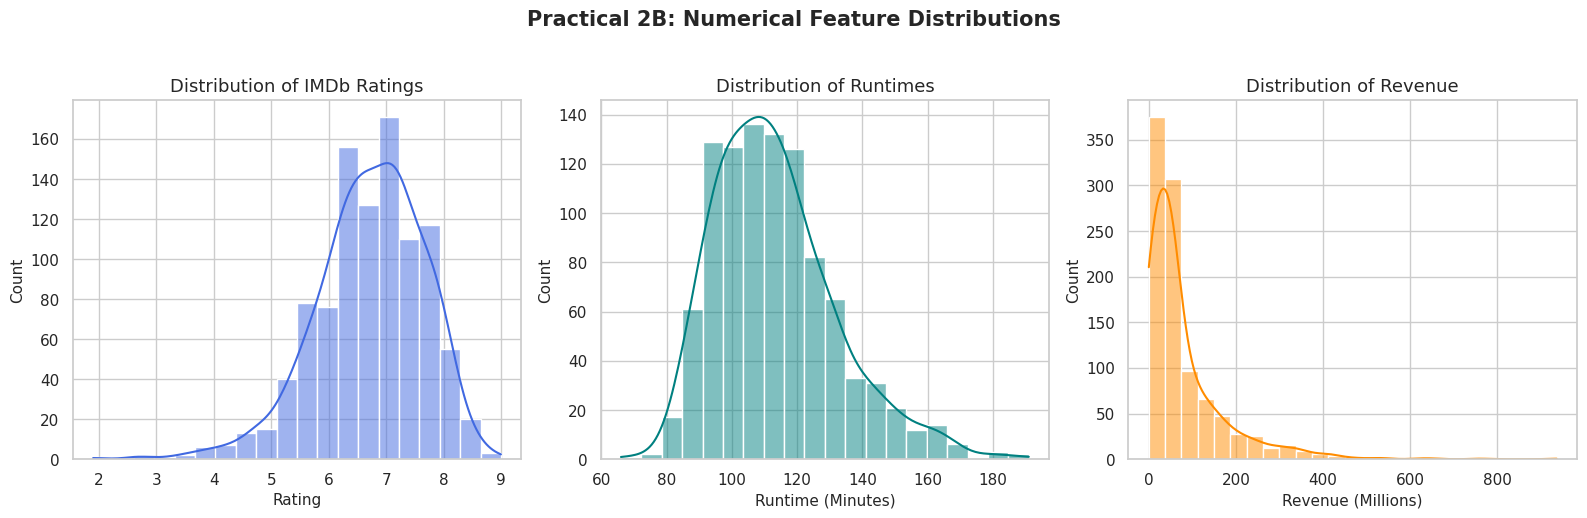


[Practical 3] Probability of Rating > 8.0: 8.83%
[Practical 4] Population Revenue Skew: 2.85 | Sample Means Skew (n=40): 0.51

[Practical 5 Z-Test] Z = 7.47, p-value = 8.2823e-14
[Practical 6 ANOVA] F-stat = 12.81, p-value = 1.1078e-24

--- Multiple Linear Regression Summary ---
                            OLS Regression Results                            
Dep. Variable:                 Rating   R-squared:                       0.526
Model:                            OLS   Adj. R-squared:                  0.524
Method:                 Least Squares   F-statistic:                     367.9
Date:                Thu, 29 Oct 2026   Prob (F-statistic):          8.96e-161
Time:                        04:45:26   Log-Likelihood:                -989.40
No. Observations:                1000   AIC:                             1987.
Df Residuals:                     996   BIC:                             2006.
Df Model:                           3                                         
Covarian

In [64]:
# ==============================================================================
# STATISTICAL ANALYSIS, INFERENCE & GRADIO UI DASHBOARD
# Assumes `df` is already loaded and preprocessed in your Colab environment
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import gradio as gr

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.autolayout": True,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11
})

# Ensure necessary helper columns exist
if 'Primary_Genre' not in df.columns:
    df['Primary_Genre'] = df['Genre'].apply(lambda x: str(x).split(',')[0])
if 'Log_Votes' not in df.columns:
    df['Log_Votes'] = np.log10(df['Votes'])

# ==============================================================================
# 1. DESCRIPTIVE STATISTICS & VISUALIZATIONS (Practicals 2A & 2B)
# ==============================================================================
target_cols = ['Rating', 'Runtime (Minutes)', 'Metascore', 'Votes', 'Revenue (Millions)']
desc_stats = pd.DataFrame(index=target_cols)
desc_stats['Mean'] = df[target_cols].mean()
desc_stats['Median'] = df[target_cols].median()
desc_stats['Std_Dev'] = df[target_cols].std()
desc_stats['IQR'] = df[target_cols].quantile(0.75) - df[target_cols].quantile(0.25)

print("--- Descriptive Statistics ---")
print(desc_stats.round(2))

# Inline Visualizations (Plot 1: Histograms)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sns.histplot(df['Rating'], kde=True, color='royalblue', bins=20, ax=axes[0])
axes[0].set_title('Distribution of IMDb Ratings')
sns.histplot(df['Runtime (Minutes)'], kde=True, color='teal', bins=20, ax=axes[1])
axes[1].set_title('Distribution of Runtimes')
sns.histplot(df['Revenue (Millions)'], kde=True, color='darkorange', bins=25, ax=axes[2])
axes[2].set_title('Distribution of Revenue')
plt.suptitle('Practical 2B: Numerical Feature Distributions', fontsize=15, fontweight='bold', y=1.03)
plt.show()

# ==============================================================================
# 2. PROBABILITY, SAMPLING & CLT (Practicals 3 & 4)
# ==============================================================================
mu, std = stats.norm.fit(df['Rating'])
prob_gt_8 = 1 - stats.norm.cdf(8.0, loc=mu, scale=std)
print(f"\n[Practical 3] Probability of Rating > 8.0: {prob_gt_8*100:.2f}%")

pop_rev = df['Revenue (Millions)']
sample_means = [pop_rev.sample(n=40, replace=True).mean() for _ in range(1000)]
print(f"[Practical 4] Population Revenue Skew: {pop_rev.skew():.2f} | Sample Means Skew (n=40): {pd.Series(sample_means).skew():.2f}")

# ==============================================================================
# 3. HYPOTHESIS TESTING & ANOVA (Practicals 5 & 6)
# ==============================================================================
mean_rating = df['Rating'].mean()
se_rating = stats.sem(df['Rating'])
z_stat = (mean_rating - 6.5) / se_rating
p_val_z = 2 * (1 - stats.norm.cdf(abs(z_stat)))
print(f"\n[Practical 5 Z-Test] Z = {z_stat:.2f}, p-value = {p_val_z:.4e}")

genre_groups = [group['Rating'].values for _, group in df.groupby('Primary_Genre')]
f_stat, p_val_anova = stats.f_oneway(*genre_groups)
print(f"[Practical 6 ANOVA] F-stat = {f_stat:.2f}, p-value = {p_val_anova:.4e}")

# ==============================================================================
# 4. MULTIPLE LINEAR REGRESSION (Practical 7)
# ==============================================================================
X = sm.add_constant(df[['Metascore', 'Runtime (Minutes)', 'Log_Votes']])
y = df['Rating']
model = sm.OLS(y, X).fit()
print("\n--- Multiple Linear Regression Summary ---")
print(model.summary())

# ==============================================================================
# UI HELPER FUNCTIONS
# ==============================================================================

def get_descriptive_stats_ui():
    """Formats and returns the pre-computed descriptive statistics DataFrame for Gradio output."""
    return desc_stats.round(2).reset_index().rename(columns={'index': 'Feature'})

def predict_imdb_rating_ui(metascore, runtime, votes):
    """Predicts the IMDb rating using the trained statsmodels OLS model parameters."""
    log_votes = np.log10(votes) if votes > 0 else 0
    pred_input = pd.DataFrame([{
        'const': 1.0,
        'Metascore': metascore,
        'Runtime (Minutes)': runtime,
        'Log_Votes': log_votes
    }])
    prediction = model.predict(pred_input)[0]
    return f"Predicted IMDb Rating: {prediction:.2f} / 10"

def generate_distribution_plot_ui(feature):
    """Generates and returns a matplotlib figure object for Gradio gr.Plot()"""
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.histplot(df[feature], kde=True, color='teal', bins=25, ax=ax)
    ax.set_title(f'Distribution Analysis: {feature}', fontsize=12, fontweight='bold')
    ax.set_xlabel(feature)
    ax.set_ylabel('Frequency')
    plt.tight_layout()
    return fig



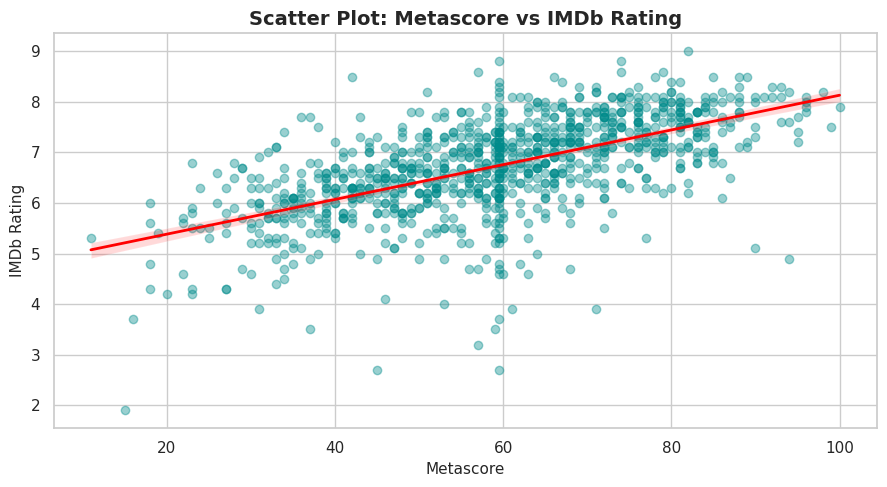

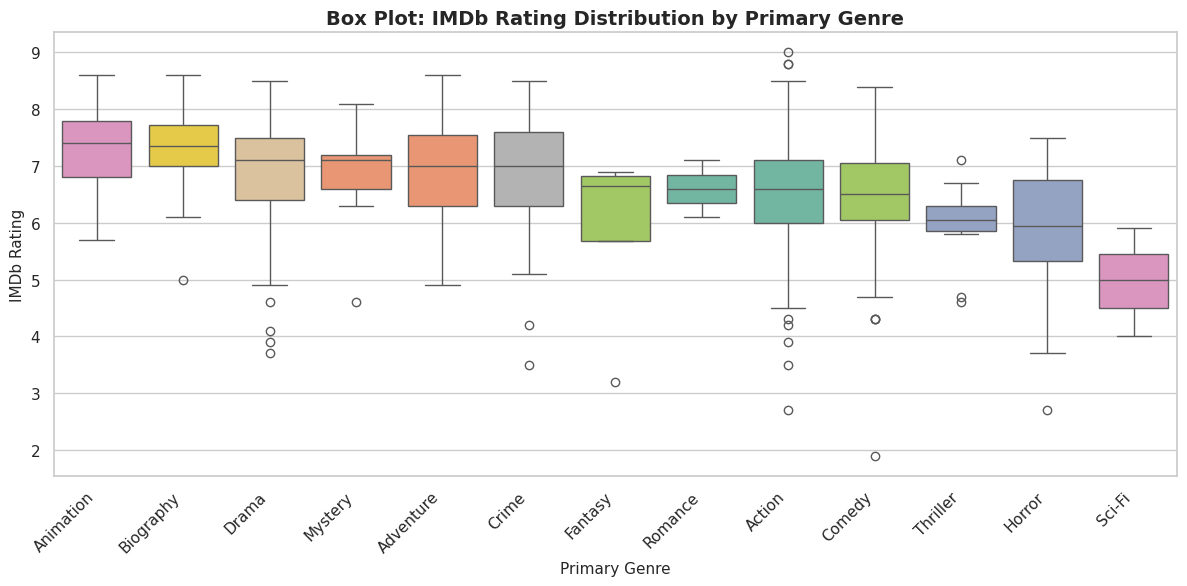

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Scatter Plot: Metascore vs IMDb Rating with Regression Line ---
plt.figure(figsize=(9, 5))
sns.regplot(data=df, x='Metascore', y='Rating', color='teal', scatter_kws={'alpha':0.4, 'color':'darkcyan'}, line_kws={'color':'red', 'linewidth':2})
plt.title('Scatter Plot: Metascore vs IMDb Rating', fontsize=14, fontweight='bold')
plt.xlabel('Metascore')
plt.ylabel('IMDb Rating')
plt.tight_layout()
plt.show()

# --- 2. Box Plot: IMDb Rating Distribution by Primary Genre ---
plt.figure(figsize=(12, 6))
# Sort genres by median rating to make the plot look organized
genre_order = df.groupby('Primary_Genre')['Rating'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='Primary_Genre', y='Rating', order=genre_order, hue='Primary_Genre', palette='Set2', legend=False)
plt.xticks(rotation=45, ha='right')
plt.title('Box Plot: IMDb Rating Distribution by Primary Genre', fontsize=14, fontweight='bold')
plt.xlabel('Primary Genre')
plt.ylabel('IMDb Rating')
plt.tight_layout()
plt.show()

In [66]:

# GRADIO UI DASHBOARD

import gradio as gr
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

def get_descriptive_stats_ui():
    return desc_stats.round(2).reset_index().rename(columns={'index': 'Feature'})

def predict_imdb_rating_ui(metascore, runtime, votes):
    log_votes = np.log10(votes) if votes > 0 else 0
    pred_input = pd.DataFrame([{
        'const': 1.0,
        'Metascore': metascore,
        'Runtime (Minutes)': runtime,
        'Log_Votes': log_votes
    }])
    prediction = model.predict(pred_input)[0]
    return f"Predicted IMDb Rating: {prediction:.2f} / 10"

def generate_distribution_plot_ui(feature):
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.histplot(df[feature], kde=True, color='teal', bins=25, ax=ax)
    ax.set_title(f'Distribution Analysis: {feature}', fontsize=12, fontweight='bold')
    ax.set_xlabel(feature)
    ax.set_ylabel('Frequency')
    plt.tight_layout()
    return fig

def generate_scatter_plot_ui():
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.regplot(data=df, x='Metascore', y='Rating', color='teal',
                scatter_kws={'alpha':0.4, 'color':'darkcyan'}, line_kws={'color':'red', 'linewidth':2}, ax=ax)
    ax.set_title('Scatter Plot: Metascore vs IMDb Rating', fontsize=12, fontweight='bold')
    ax.set_xlabel('Metascore')
    ax.set_ylabel('IMDb Rating')
    plt.tight_layout()
    return fig

def generate_box_plot_ui():
    fig, ax = plt.subplots(figsize=(10, 5))
    genre_order = df.groupby('Primary_Genre')['Rating'].median().sort_values(ascending=False).index
    sns.boxplot(data=df, x='Primary_Genre', y='Rating', order=genre_order, hue='Primary_Genre', palette='Set2', legend=False, ax=ax)
    plt.xticks(rotation=45, ha='right')
    ax.set_title('IMDb Rating Distribution by Primary Genre', fontsize=12, fontweight='bold')
    ax.set_xlabel('Primary Genre')
    ax.set_ylabel('IMDb Rating')
    plt.tight_layout()
    return fig

with gr.Blocks() as demo_updated:
    gr.Markdown("# 🎬 IMDb Movie Data: Statistical Analysis & Inference Dashboard")

    with gr.Tabs():
        with gr.TabItem("📊 Descriptive Statistics"):
            stats_output = gr.Dataframe(value=get_descriptive_stats_ui(), interactive=False)
            btn_refresh = gr.Button("Reload Statistics")
            btn_refresh.click(fn=get_descriptive_stats_ui, outputs=stats_output)

        with gr.TabItem("📈 Visualizations"):
            with gr.Row():
                plot_type = gr.Radio(
                    choices=["Histogram / Distribution", "Scatter Plot (Metascore vs Rating)", "Box Plot (Rating by Genre)"],
                    value="Histogram / Distribution",
                    label="Select Plot Type"
                )
                feature_dropdown = gr.Dropdown(
                    choices=['Rating', 'Runtime (Minutes)', 'Metascore', 'Votes', 'Revenue (Millions)'],
                    value='Rating',
                    label="Feature (for Histogram/Distribution only)"
                )

            plot_output = gr.Plot()

            def update_dashboard_plot(selected_type, feature):
                if selected_type == "Histogram / Distribution":
                    return generate_distribution_plot_ui(feature)
                elif selected_type == "Scatter Plot (Metascore vs Rating)":
                    return generate_scatter_plot_ui()
                elif selected_type == "Box Plot (Rating by Genre)":
                    return generate_box_plot_ui()

            # Set event listeners
            plot_type.change(fn=update_dashboard_plot, inputs=[plot_type, feature_dropdown], outputs=plot_output)
            feature_dropdown.change(fn=update_dashboard_plot, inputs=[plot_type, feature_dropdown], outputs=plot_output)

            # Load initial state
            demo_updated.load(fn=lambda: generate_distribution_plot_ui('Rating'), outputs=plot_output)

        with gr.TabItem("🤖 Regression Predictor"):
            with gr.Row():
                slider_meta = gr.Slider(minimum=20, maximum=100, value=75, step=1, label="Metascore")
                slider_runtime = gr.Slider(minimum=80, maximum=200, value=120, step=1, label="Runtime")
                slider_votes = gr.Slider(minimum=1000, maximum=1000000, value=150000, step=1000, label="Votes")
            prediction_output = gr.Textbox(label="Prediction")
            btn_predict = gr.Button("Calculate Rating", variant="primary")
            btn_predict.click(fn=predict_imdb_rating_ui, inputs=[slider_meta, slider_runtime, slider_votes], outputs=prediction_output)

demo_updated.launch(inline=True, share=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>